<a href="https://colab.research.google.com/github/James007Bond-code/BLM5103-Proje1-Grup03/blob/main/BIL545_Proje1_Beijing_PM25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BIL545 · Proje 1 · Beijing PM2.5 kirlilik epizotları

**Grup adı:** _(doldurun)_
**Üyeler:** _(ad soyad · öğrenci no)_
**İletişim sorumlusu:** _(doldurun)_
**Konu:** 9.7 Hava kalitesi ve kirlilik epizotları · **Veri:** UCI Beijing PM2.5 (PRSA, 2010–2014, saatlik)

## 0. Hazırlık

In [1]:
# Gerekli ek kütüphane (birliktelik analizi için)
!pip install -q mlxtend

import sys
import warnings
import numpy as np
import pandas as pd
import sklearn
import scipy
import matplotlib
import matplotlib.pyplot as plt
import mlxtend

from scipy import stats
from scipy.stats import binomtest, chi2
from sklearn.base import clone
from sklearn.model_selection import (TimeSeriesSplit, StratifiedKFold, GridSearchCV,
                                     cross_val_score, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import f1_score
from sklearn.inspection import permutation_importance
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Kütüphane sürümleri (yönerge 3.3)
print("=== KÜTÜPHANE SÜRÜMLERİ ===")
print(f"Python       : {sys.version.split()[0]}")
print(f"Pandas       : {pd.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"Scikit-learn : {sklearn.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")
print(f"mlxtend      : {mlxtend.__version__}")

# 2. Rastgelelik tohumu (tekrarlanabilirlik)
SEED = 42
np.random.seed(SEED)
print("\nRastgelelik tohumu (SEED) 42 olarak sabitlendi.")

=== KÜTÜPHANE SÜRÜMLERİ ===
Python       : 3.13.18
Pandas       : 2.2.3
NumPy        : 2.4.6
Scikit-learn : 1.6.1
SciPy        : 1.16.3
Matplotlib   : 3.10.0
mlxtend      : 0.23.4

Rastgelelik tohumu (SEED) 42 olarak sabitlendi.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Okuma notları
- **Kaufman vd. (2012), Leakage in data mining:** _(2–3 cümle: sızıntı türleri, bu veride hangisi geçerli)_
- **Dietterich (1998), Approximate statistical tests:** _(2–3 cümle: neden kat skorlarında t-testi değil, McNemar / 5×2 cv)_
- **Wu, Chen ve Han (2010), Interestingness measures:** _(2–3 cümle: null-invariance, Kulczynski, dengesizlik oranı)_

In [2]:
# UCI Beijing PM2.5 verisini kaynaktan doğrudan çekme
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00381/PRSA_data_2010.1.1-2014.12.31.csv"
df = pd.read_csv(url)

print(f"Veri boyutu: {df.shape[0]} satır, {df.shape[1]} sütun.")
df.head()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Veri boyutu: 43824 satır, 13 sütun.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Bölüm 1 · Veri, ön işleme ve sızıntı

### 1.1 Veri künyesi
- **Kim, hangi amaçla topladı:** _(Liang vd., 2015; ABD Büyükelçiliği PM2.5 ölçümleri + Pekin Havaalanı meteoroloji verisi)_
- **Dönem:** 1 Ocak 2010 – 31 Aralık 2014, saatlik
- **Hedef gerçek olgu mu, vekil mi:** _(tek istasyon ölçümü → bütün şehir için vekil)_
- **Kimler eksik temsil ediliyor olabilir:** _(tek bir noktadaki ölçüm; şehrin diğer bölgeleri, iç mekân maruziyeti)_
- **Lisans:** _(UCI sayfasından doğrulayın: CC BY 4.0)_

### 1.2 Keşifsel analiz

In [3]:
ham = df.drop(columns=['No'])
eda = pd.DataFrame({
    'tip': ham.dtypes.astype(str),
    'olcek': ['aralık (yıl)', 'sıralı/döngüsel', 'sıralı/döngüsel', 'sıralı/döngüsel', 'oran (µg/m³)',
              'aralık (°C)', 'aralık (°C)', 'oran (hPa)', 'nominal', 'oran (m/s, birikimli)',
              'oran (saat, birikimli)', 'oran (saat, birikimli)'],
    'eksik_%': (ham.isna().mean() * 100).round(2),
    'farkli_deger': ham.nunique(),
    'sifir_%': (ham.apply(lambda s: (s == 0).mean() if s.dtype.kind in 'if' else 0.0) * 100).round(2),
})
display(eda)

print("Yinelenen satır (bütün sütunlar)          :", ham.duplicated().sum())
print("Yinelenen zaman damgası (yıl-ay-gün-saat) :", ham.duplicated(subset=['year', 'month', 'day', 'hour']).sum())
print("Hedef hariç aynı olan satır               :", ham.drop(columns=['pm2.5']).duplicated().sum())

# Şüpheli öznitelikler:
#  - No: satır numarası (kimlik benzeri) → çıkarılacak
#  - pm2.5: hedefin kaynağı → girdiden çıkarılacak
#  - year: zamana göre bölmede test yılı eğitimde hiç görülmez; ağaçlar dışa değer tahmini yapamaz
#  - day: ayın günü, fiziksel bir anlamı yok
#  - Iws / Is / Ir: birikimli değişkenler (aynı koşulun kaç saattir sürdüğü)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,tip,olcek,eksik_%,farkli_deger,sifir_%
year,int64,aralık (yıl),0.00,5,0.00
month,int64,sıralı/döngüsel,0.00,12,0.00
day,int64,sıralı/döngüsel,0.00,31,0.00
hour,int64,sıralı/döngüsel,0.00,24,4.17
pm2.5,float64,oran (µg/m³),4.72,581,0.00
DEWP,int64,aralık (°C),0.00,69,1.90
TEMP,float64,aralık (°C),0.00,64,2.59
PRES,float64,oran (hPa),0.00,60,0.00
cbwd,object,nominal,0.00,4,0.00
Iws,float64,"oran (m/s, birikimli)",0.00,2788,0.00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Yinelenen satır (bütün sütunlar)          : 0
Yinelenen zaman damgası (yıl-ay-gün-saat) : 0
Hedef hariç aynı olan satır               : 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum:** _(Hangi sütunlar şüpheli, neden? year ve day tutuldu mu, gerekçesi ne? Yinelenen kayıt var mı?)_

### 1.3 Eksiklik analizi

In [4]:
eksik = df['pm2.5'].isna()
print(f"pm2.5 eksik: {eksik.sum()} satır (%{eksik.mean()*100:.2f})")
print("Diğer sütunlardaki toplam eksik:", int(df.drop(columns=['pm2.5']).isna().sum().sum()))
# Bu veride eksikler NaN olarak geliyor; -999 gibi kodlanmış eksik yok (yukarıdaki tablo ile doğrulayın).

# 1) Zaman deseni: yıl × ay eksik oranı (%)
print("\nYıl × ay eksik oranı (%)")
display((df.assign(eksik=eksik)
           .pivot_table(index='year', columns='month', values='eksik', aggfunc='mean') * 100).round(1))

# 2) Eksikler ardışık bloklar hâlinde mi? (cihaz arızası → uzun bloklar; rastgele → tek tek saatler)
blok_id = (eksik != eksik.shift()).cumsum()
bloklar = eksik[eksik].groupby(blok_id[eksik]).size()
print(f"Eksik blok sayısı: {len(bloklar)} · medyan uzunluk: {bloklar.median():.0f} saat · "
      f"en uzun: {bloklar.max()} saat · 24 saatten uzun blok: {(bloklar > 24).sum()}")

# 3) MAR mı? Eksik saatlerde hava koşulları farklı mı?
print("\nHava değişkenlerinin ortalaması: pm2.5 var / eksik")
display(df.groupby(eksik)[['DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir']].mean()
          .rename(index={False: 'pm2.5 var', True: 'pm2.5 eksik'}).round(2))
display(pd.crosstab(eksik.map({False: 'pm2.5 var', True: 'pm2.5 eksik'}), df['cbwd'], normalize='index').round(3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

pm2.5 eksik: 2067 satır (%4.72)
Diğer sütunlardaki toplam eksik: 0

Yıl × ay eksik oranı (%)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2010,12.2,0.1,4.7,0.3,0.9,21.5,0.0,9.1,35.0,0.3,7.8,0.0
2011,9.7,0.0,16.0,25.6,4.3,1.2,0.4,23.4,0.1,17.2,0.7,0.1
2012,9.9,0.9,0.5,0.1,7.1,1.7,7.5,16.3,0.8,0.5,3.1,17.5
2013,0.7,0.1,0.7,0.7,2.3,0.3,0.9,1.2,0.4,0.8,0.3,2.7
2014,0.9,0.4,0.1,0.4,0.3,2.4,0.9,1.5,0.7,0.1,1.9,3.8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Eksik blok sayısı: 214 · medyan uzunluk: 1 saat · en uzun: 155 saat · 24 saatten uzun blok: 20

Hava değişkenlerinin ortalaması: pm2.5 var / eksik


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,DEWP,TEMP,PRES,Iws,Is,Ir
pm2.5,,,,,,
pm2.5 var,1.75,12.4,1016.44,23.87,0.06,0.19
pm2.5 eksik,3.17,13.4,1016.54,24.34,0.00,0.20


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

cbwd,NE,NW,SE,cv
pm2.5,,,,
pm2.5 eksik,0.117,0.322,0.347,0.214
pm2.5 var,0.114,0.323,0.349,0.214


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum:** _(Eksiklik yalnızca hedefte, yani "en çok eksiği olan iki sütun" yok; bunu açıkça yazın. Bloklar uzun ve belli dönemlerde toplanıyorsa cihaz kaynaklı: MCAR'a yakın ama dönem bağımlı → MAR. Yüksek kirlilikte ölçüm yapılamıyorsa MNAR olurdu; bunu veriyle sınayamayız. Öznitelikte eksik olmadığı için add_indicator bu veride etkisizdir. Hedefi eksik satırlar çıkarıldı, çünkü hedef doldurulamaz.)_

### 1.4 Temizleme ve hedef

In [5]:
# 1. Ham verinin kopyası
df_clean = df.copy()

# 2. 'No' kimlik sütununu kaldırma (Kaufman vd., 2012: kimlik benzeri sütunlar)
df_clean = df_clean.drop(columns=['No'])

# 3. Yıl, ay, gün, saati tek bir datetime sütununa dönüştürme ve sıralama
df_clean['datetime'] = pd.to_datetime(df_clean[['year', 'month', 'day', 'hour']])
df_clean = df_clean.sort_values('datetime').reset_index(drop=True)

# 4. Hedefi eksik satırları çıkarma
print(f"Ham veri satır sayısı: {len(df_clean)}")
df_clean = df_clean.dropna(subset=['pm2.5']).reset_index(drop=True)
print(f"Hedefi dolu satır sayısı: {len(df_clean)}")

# 5. PM2.5'i ikili sınıfa çevirme: epizot = PM2.5 > 75 µg/m³
#    75 µg/m³, Çin GB 3095-2012 standardının 24 saatlik II. sınıf sınırıdır.
#    Burada saatlik değere uygulanıyor (varsayım defterine yazıldı).
df_clean['kirlilik_epizodu'] = (df_clean['pm2.5'] > 75).astype(int)

# 6. Sınıf dağılımı
oranlar = df_clean['kirlilik_epizodu'].value_counts(normalize=True) * 100
print("\n--- Sınıf Dağılımı ---")
print(f"0 (Temiz Hava)      : %{oranlar[0]:.2f}")
print(f"1 (Kirlilik Epizodu): %{oranlar[1]:.2f}")

df_clean[['datetime', 'pm2.5', 'kirlilik_epizodu', 'TEMP', 'PRES', 'cbwd', 'Iws']].head()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Ham veri satır sayısı: 43824
Hedefi dolu satır sayısı: 41757

--- Sınıf Dağılımı ---
0 (Temiz Hava)      : %51.51
1 (Kirlilik Epizodu): %48.49


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,datetime,pm2.5,kirlilik_epizodu,TEMP,PRES,cbwd,Iws
0,2010-01-02 00:00:00,129.0,1,-4.0,1020.0,SE,1.79
1,2010-01-02 01:00:00,148.0,1,-4.0,1020.0,SE,2.68
2,2010-01-02 02:00:00,159.0,1,-5.0,1021.0,SE,3.57
3,2010-01-02 03:00:00,181.0,1,-5.0,1022.0,SE,5.36
4,2010-01-02 04:00:00,138.0,1,-5.0,1022.0,SE,6.25


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [6]:
# Girdilerden çıkarılacak sütunlar:
# - 'pm2.5': hedef bundan türetildi → modelde kalırsa doğrudan sızıntı
# - 'kirlilik_epizodu': hedef (y)
# - 'datetime': yalnızca sıralama için
# Tahmin anı: aynı saatin hava koşullarıyla aynı saatin epizodu (anlık tespit, erken uyarı değil).
drop_cols = ['datetime', 'pm2.5', 'kirlilik_epizodu']

X = df_clean.drop(columns=drop_cols)
y = df_clean['kirlilik_epizodu']

cat_cols = ['cbwd']                                   # rüzgâr yönü
num_cols = [c for c in X.columns if c not in cat_cols]

print(f"Öznitelik sayısı: {X.shape[1]}")
print("Sayısal sütunlar :", num_cols)
print("Kategorik sütun  :", cat_cols)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Öznitelik sayısı: 11
Sayısal sütunlar : ['year', 'month', 'day', 'hour', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir']
Kategorik sütun  : ['cbwd']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [7]:
# Dokunulmayan zamansal test kümesi: son %20.
# Model seçimi, ayar ve karşılaştırmalar yalnızca ilk %80'de (geliştirme) yapılır;
# son %20 yalnızca McNemar testi ve Ek paket 1'de bir kez kullanılır.
split_idx = int(len(X) * 0.8)
X_dev, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_dev, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# 5 katlı zamana göre çapraz doğrulama. gap=24: eğitim katının sonu ile test katının başı
# arasında 24 saat boşluk. Ardışık saatler neredeyse aynı olduğu için sınırdan sızıntıyı önler.
tscv = TimeSeriesSplit(n_splits=5, gap=24)

print("Geliştirme:", df_clean['datetime'].iloc[0], "→", df_clean['datetime'].iloc[split_idx - 1], f"({len(X_dev)} saat)")
print("Test      :", df_clean['datetime'].iloc[split_idx], "→", df_clean['datetime'].iloc[-1], f"({len(X_test)} saat)")
print(f"Epizot oranı · geliştirme: %{y_dev.mean()*100:.1f} · test: %{y_test.mean()*100:.1f}")

Geliştirme: 2010-01-02 00:00:00 → 2014-01-14 01:00:00 (33405 saat)
Test      : 2014-01-14 02:00:00 → 2014-12-31 23:00:00 (8352 saat)
Epizot oranı · geliştirme: %48.7 · test: %47.8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### 1.5 Sızıntı deneyi, baseline ve ilk model

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

=== SIZINTI DENEYİ VE BASELINE (F1, pozitif sınıf: epizot) ===
Baseline (Dummy)                    : 0.1188 ± 0.2377
Lojistik regresyon · sızıntılı      : 0.6740 ± 0.1083
Lojistik regresyon · doğru (Pipeline): 0.6679 ± 0.1199


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

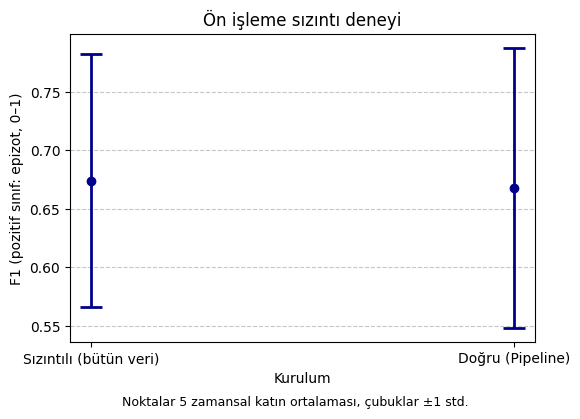

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [8]:
# -------------------------------------------------------------
# 1. DOĞRU KURULUM: ön işleme Pipeline içinde (her katta yalnız eğitim verisiyle fit)
# -------------------------------------------------------------
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

pipeline_dogru = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=SEED))
])
scores_dogru = cross_val_score(pipeline_dogru, X_dev, y_dev, cv=tscv, scoring='f1')

# Baseline: aynı sızıntısız hatta DummyClassifier
pipeline_dummy = Pipeline([('preprocessor', preprocessor),
                           ('classifier', DummyClassifier(strategy='most_frequent'))])
with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # Dummy hiç pozitif tahmin etmediği için F1 = 0 uyarısı
    scores_dummy = cross_val_score(pipeline_dummy, X_dev, y_dev, cv=tscv, scoring='f1')

# -------------------------------------------------------------
# 2. HATALI KURULUM: ön işleme bütün geliştirme verisinde bir kez (sızıntılı)
# -------------------------------------------------------------
X_hatali = X_dev.copy()
num_imp = SimpleImputer(strategy='median').fit_transform(X_hatali[num_cols])
scaled = StandardScaler().fit_transform(num_imp)
cat_imp = SimpleImputer(strategy='most_frequent').fit_transform(X_hatali[cat_cols])
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore').fit_transform(cat_imp)
X_hatali_processed = np.hstack([scaled, ohe])

model_hatali = LogisticRegression(max_iter=1000, random_state=SEED)
scores_hatali = cross_val_score(model_hatali, X_hatali_processed, y_dev, cv=tscv, scoring='f1')

# -------------------------------------------------------------
# Sonuçlar (ortalama ± std)
# -------------------------------------------------------------
print("=== SIZINTI DENEYİ VE BASELINE (F1, pozitif sınıf: epizot) ===")
print(f"Baseline (Dummy)                    : {scores_dummy.mean():.4f} ± {scores_dummy.std():.4f}")
print(f"Lojistik regresyon · sızıntılı      : {scores_hatali.mean():.4f} ± {scores_hatali.std():.4f}")
print(f"Lojistik regresyon · doğru (Pipeline): {scores_dogru.mean():.4f} ± {scores_dogru.std():.4f}")

plt.figure(figsize=(6, 4))
plt.errorbar(
    ['Sızıntılı (bütün veri)', 'Doğru (Pipeline)'],
    [scores_hatali.mean(), scores_dogru.mean()],
    yerr=[scores_hatali.std(), scores_dogru.std()],
    fmt='o', capsize=8, capthick=2, elinewidth=2, color='darkblue'
)
plt.xlabel('Kurulum')
plt.ylabel('F1 (pozitif sınıf: epizot, 0–1)')
plt.title('Ön işleme sızıntı deneyi')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.figtext(0.5, -0.05, 'Noktalar 5 zamansal katın ortalaması, çubuklar ±1 std.', ha='center', fontsize=9)
plt.show()

**Yorum:** _(Fark büyük mü küçük mü? Öznitelikte eksik yok ve ölçekleme lojistik regresyonu az etkiler; fark küçükse nedeni bu. Bu verideki asıl sızıntı riski zamansal: bkz. 1.7 Weka karşılaştırması. Neden tekrarlı katmanlı CV değil de TimeSeriesSplit: zaman serisinde karıştırma geleceği eğitime sızdırır, Kaufman vd. 2012.)_

### 1.6 Kategorik kodlama

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

yon_ay_saat: 1152 kategori · 20'den az kayıtlı kategori: 474 · medyan kayıt: 24


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datet

,F1 ortalama,F1 std
Bire-bir,0.6866,0.1219
"Bire-bir, nadirler birleşik (<20)",0.6786,0.1237
Kat dışı hedef kodlama,0.6663,0.1177
Hedef kodlama · YANLIŞ (bütün veride),0.6741,0.1109


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

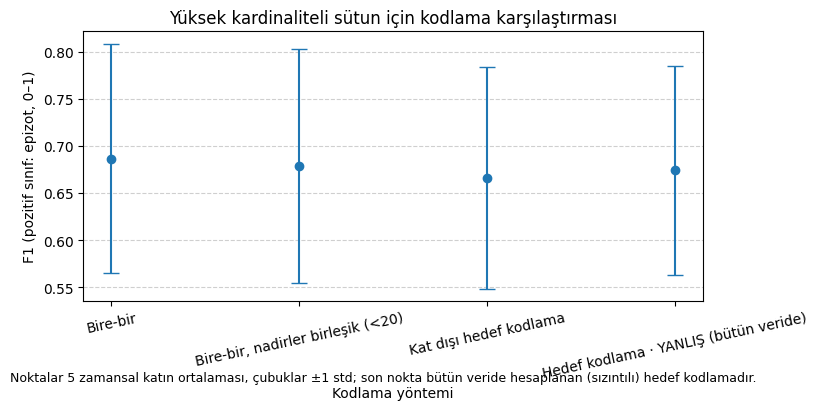

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [9]:
# Veride yüksek kardinaliteli kategorik yok (cbwd yalnızca 4 değer). Alan bilgisiyle anlamlı bir tane
# türetiyoruz: rüzgâr yönü × ay × saat. Rüzgâr yönünün etkisi mevsime ve günün saatine göre değişir.
YK = 'yon_ay_saat'

def kard_ekle(X_):
    X_ = X_.copy()
    X_[YK] = X_['cbwd'].astype(str) + '_' + X_['month'].astype(str) + '_' + X_['hour'].astype(str)
    return X_

X_dev_k = kard_ekle(X_dev)
sayim = X_dev_k[YK].value_counts()
print(f"{YK}: {sayim.size} kategori · 20'den az kayıtlı kategori: {(sayim < 20).sum()} · medyan kayıt: {sayim.median():.0f}")

def kod_hatti(kodlayici, yk_sayisal=False):
    if yk_sayisal:   # yanlış kurulum: sütun önceden sayıya çevrilmiş geliyor
        pre = ColumnTransformer([('num', num_transformer, num_cols + [YK]),
                                 ('cbwd', OneHotEncoder(handle_unknown='ignore'), ['cbwd'])])
    else:
        pre = ColumnTransformer([('num', num_transformer, num_cols),
                                 ('cbwd', OneHotEncoder(handle_unknown='ignore'), ['cbwd']),
                                 ('yk', kodlayici, [YK])])
    return Pipeline([('preprocessor', pre),
                     ('classifier', LogisticRegression(max_iter=2000, random_state=SEED))])

kodlamalar = {
    'Bire-bir': OneHotEncoder(handle_unknown='ignore'),
    'Bire-bir, nadirler birleşik (<20)': OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20),
    'Kat dışı hedef kodlama': TargetEncoder(target_type='binary', random_state=SEED),
}
kod_sonuc = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore', FutureWarning)
    for ad, kod in kodlamalar.items():
        kod_sonuc[ad] = cross_val_score(kod_hatti(kod), X_dev_k, y_dev, cv=tscv, scoring='f1')

# YANLIŞ: hedef ortalaması bütün geliştirme verisinden (gelecek dahil) bir kez hesaplanıyor
yanlis_harita = X_dev_k.assign(_y=y_dev.values).groupby(YK)['_y'].mean()
X_dev_yanlis = X_dev_k.copy()
X_dev_yanlis[YK] = X_dev_k[YK].map(yanlis_harita)
kod_sonuc['Hedef kodlama · YANLIŞ (bütün veride)'] = cross_val_score(
    kod_hatti(None, yk_sayisal=True), X_dev_yanlis, y_dev, cv=tscv, scoring='f1')

kod_tablo = pd.DataFrame({'F1 ortalama': {k: v.mean() for k, v in kod_sonuc.items()},
                          'F1 std': {k: v.std() for k, v in kod_sonuc.items()}}).round(4)
display(kod_tablo)

plt.figure(figsize=(8, 3.5))
plt.errorbar(kod_tablo.index, kod_tablo['F1 ortalama'], yerr=kod_tablo['F1 std'], fmt='o', capsize=6)
plt.ylabel('F1 (pozitif sınıf: epizot, 0–1)')
plt.xlabel('Kodlama yöntemi')
plt.xticks(rotation=12)
plt.title('Yüksek kardinaliteli sütun için kodlama karşılaştırması')
plt.figtext(0.5, -0.12, 'Noktalar 5 zamansal katın ortalaması, çubuklar ±1 std; son nokta bütün veride '
            'hesaplanan (sızıntılı) hedef kodlamadır.', ha='center', fontsize=9)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

**Yorum:** _(Yanlış hedef kodlama ne kadar şişirdi? Nadir kategorileri birleştirmek ne değiştirdi? Hangi kodlama seçildi ve neden?)_

### 1.7 Weka ile bağımsız kontrol (ZeroR ve J48, 10 kat)

In [10]:
# Weka için ARFF dosyası
weka_export = df_clean.drop(columns=['pm2.5', 'datetime']).copy()
weka_export['kirlilik_epizodu'] = weka_export['kirlilik_epizodu'].map({0: 'HAYIR', 1: 'EVET'})

arff_lines = [
    "@relation beijing_pm25\n",
    "@attribute year numeric",
    "@attribute month numeric",
    "@attribute day numeric",
    "@attribute hour numeric",
    "@attribute DEWP numeric",
    "@attribute TEMP numeric",
    "@attribute PRES numeric",
    "@attribute cbwd {NE,NW,SE,cv}",
    "@attribute Iws numeric",
    "@attribute Is numeric",
    "@attribute Ir numeric",
    "@attribute kirlilik_epizodu {HAYIR,EVET}\n",
    "@data"
]
for row in weka_export.itertuples(index=False):
    arff_lines.append(",".join(str(v) if pd.notnull(v) else '?' for v in row))

with open("beijing_weka.arff", "w") as f:
    f.write("\n".join(arff_lines))
print("beijing_weka.arff oluşturuldu. Weka Explorer → Classify → ZeroR ve J48, Cross-validation Folds = 10.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

beijing_weka.arff oluşturuldu. Weka Explorer → Classify → ZeroR ve J48, Cross-validation Folds = 10.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [11]:
# Weka "Cross-validation, Folds 10" veriyi KARIŞTIRIP katmanlı böler; Python tarafımız ise zamana göre
# böler, yani sayılar doğrudan karşılaştırılamaz. Önce Weka'nın protokolünü Python'da tekrarlıyoruz,
# sonra aynı modellerin zamana göre bölmedeki skorunu yanına koyuyoruz. (Weka bütün veriyi kullandığı için
# burada da X, y kullanılıyor.)
pre_agac = ColumnTransformer([('num', 'passthrough', num_cols),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
weka_benzeri = {
    'ZeroR ≈ Dummy(most_frequent)': DummyClassifier(strategy='most_frequent'),
    'J48 ≈ Karar ağacı (entropi, min. 2 kayıt/yaprak)': DecisionTreeClassifier(criterion='entropy', min_samples_leaf=2, random_state=SEED),
}
bolmeler = {
    '10 kat karıştırılmış (Weka gibi)': StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED),
    'Zamana göre (TimeSeriesSplit)': TimeSeriesSplit(n_splits=5, gap=24),
}
satirlar = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for m_ad, m in weka_benzeri.items():
        for b_ad, b in bolmeler.items():
            r = cross_validate(Pipeline([('pre', pre_agac), ('clf', m)]), X, y, cv=b,
                               scoring=['accuracy', 'f1'], n_jobs=-1)
            satirlar.append({'Model': m_ad, 'Bölme': b_ad,
                             'Doğruluk': f"{r['test_accuracy'].mean():.4f} ± {r['test_accuracy'].std():.4f}",
                             'F1 (EVET)': f"{r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f}"})
display(pd.DataFrame(satirlar))

# Weka çıktısından elle doldurun: "Correctly Classified Instances" (%) ve EVET satırındaki F-Measure
# Weka 3 · Explorer · Classify · Cross-validation (Folds = 10) çıktısından
weka_sonuc = pd.DataFrame({'Doğruluk (Weka)': {'ZeroR': 0.5151, 'J48 (-C 0.25 -M 2)': 0.8612},
                           'F1 EVET (Weka)': {'ZeroR': 'tanımsız (?)', 'J48 (-C 0.25 -M 2)': 0.857},
                           'Kappa (Weka)': {'ZeroR': 0.0, 'J48 (-C 0.25 -M 2)': 0.7222}})
display(weka_sonuc)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Model,Bölme,Doğruluk,F1 (EVET)
0,ZeroR ≈ Dummy(most_frequent),10 kat karıştırılmış (Weka gibi),0.5151 ± 0.0001,0.0000 ± 0.0000
1,ZeroR ≈ Dummy(most_frequent),Zamana göre (TimeSeriesSplit),0.5069 ± 0.0307,0.1263 ± 0.2525
2,"J48 ≈ Karar ağacı (entropi, min. 2 kayıt/yaprak)",10 kat karıştırılmış (Weka gibi),0.8559 ± 0.0061,0.8486 ± 0.0066
3,"J48 ≈ Karar ağacı (entropi, min. 2 kayıt/yaprak)",Zamana göre (TimeSeriesSplit),0.6954 ± 0.0144,0.6662 ± 0.0278


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Doğruluk (Weka),F1 EVET (Weka),Kappa (Weka)
ZeroR,0.5151,tanımsız (?),0.0000
J48 (-C 0.25 -M 2),0.8612,0.857,0.7222


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Weka çıktısı (özet):**

```
ZeroR · 10-fold cross-validation
ZeroR predicts class value: HAYIR
Correctly Classified Instances       21511               51.5147 %
Kappa statistic                          0
                 TP Rate  FP Rate  Precision  Recall   F-Measure  Class
                 1,000    1,000    0,515      1,000    0,680      HAYIR
                 0,000    0,000    ?          0,000    ?          EVET
Confusion Matrix:  21511 0 | HAYIR   ·   20246 0 | EVET

J48 -C 0.25 -M 2 · 10-fold cross-validation
Number of Leaves  : 2331      Size of the tree : 4547
Kök bölmesi: DEWP <= -15, ikinci düzey: Iws <= 18.33
Correctly Classified Instances       35961               86.1197 %
Kappa statistic                          0.7222
                 TP Rate  FP Rate  Precision  Recall   F-Measure  Class
                 0,861    0,139    0,868      0,861    0,865      HAYIR
                 0,861    0,139    0,854      0,861    0,857      EVET
Confusion Matrix:  18523 2988 | HAYIR   ·   2808 17438 | EVET
```

**Yorum:**

**Tutarlılık.** Weka ve Python aynı protokolde (10 katlı, karıştırılmış, katmanlı CV) tutarlı sonuç veriyor. ZeroR iki tarafta da %51,51 doğruluk veriyor; her kaydı çoğunluk sınıfı HAYIR olarak tahmin ediyor. EVET için F1 Weka'da "?" (hiç EVET tahmini olmadığı için kesinlik 0/0), scikit-learn'de 0 olarak raporlanıyor; ikisi aynı durumu anlatıyor. J48 Weka'da %86,12 doğruluk ve EVET için 0,857 F1 veriyor. Python'daki karşılığı (entropi ölçütü, yaprak başına en az 2 kayıt) %85,59 ± 0,61 doğruluk ve 0,849 ± 0,007 F1 veriyor. Aradaki yaklaşık 0,5 puanlık fark kat std'si mertebesinde. J48'in C4.5 budaması (güven faktörü 0,25) scikit-learn ağacında olmadığı için tam eşitlik beklenmiyordu. Weka 10 katın birleştirilmiş tahminlerinden tek bir değer raporluyor; std yalnızca Python tarafında var.

**Asıl bulgu, zamansal sızıntı.** Aynı ağaç zamana göre bölmeyle (TimeSeriesSplit, gap = 24) değerlendirildiğinde doğruluk %69,54 ± 1,44'e, F1 0,666 ± 0,028'e düşüyor. Karıştırılmış CV'deki yaklaşık **16 puanlık** fazlalık modelin gerçek başarımı değil, sızıntıdır. Saatlik veride ardışık saatler birbirine çok benzediği için karıştırılmış bölmede her test saatinin bir saat önceki ve sonraki komşusu eğitimde kalıyor ve model geleceği görmüş oluyor (Kaufman vd., 2012). Weka'nın kurduğu ağaç da bunu destekliyor: 2.331 yaprak, 4.547 düğüm var ve derin bölmelerde `day <= 9`, `year <= 2012` gibi fiziksel anlamı olmayan, belirli dönemleri ezberleyen koşullar görülüyor. Bu ezber karıştırılmış CV'de işe yarıyor, gelecekteki bir dönemde yaramıyor. Bu yüzden projedeki bütün karşılaştırmalar zamana göre bölmeyle yapıldı; %86'lık bir skoru raporlamak bu veri için yanıltıcı olurdu.

**Neyi söyleyemeyiz.** Weka ile tutarlılık, Python kurulumunda uygulama hatası olmadığını gösteriyor; modelin iyi olduğunu göstermiyor. İki araç da aynı sızıntılı protokolde aynı iyimser sonucu verebilir.

## Bölüm 2 · Sınıflandırma ve dürüst model değerlendirme

### 2.1 Model karşılaştırması

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Modeller zamana göre çapraz doğrulama ile değerlendiriliyor (yalnız geliştirme verisi)...

✓ Baseline (Dummy)       -> F1: 0.1188 ± 0.2377 | B-Acc: 0.5000 ± 0.0000
✓ Karar Ağacı            -> F1: 0.6765 ± 0.0932 | B-Acc: 0.6817 ± 0.0382
✓ k-NN                   -> F1: 0.6372 ± 0.0383 | B-Acc: 0.6604 ± 0.0310
✓ Rastgele Orman (RF)    -> F1: 0.7257 ± 0.0490 | B-Acc: 0.7233 ± 0.0309
✓ Gradyan Artırma (HGB)  -> F1: 0.7049 ± 0.1014 | B-Acc: 0.7279 ± 0.0476


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,F1 (ortalama ± std),Dengeli doğruluk (ortalama ± std)
Baseline (Dummy),0.1188 ± 0.2377,0.5000 ± 0.0000
Karar Ağacı,0.6765 ± 0.0932,0.6817 ± 0.0382
k-NN,0.6372 ± 0.0383,0.6604 ± 0.0310
Rastgele Orman (RF),0.7257 ± 0.0490,0.7233 ± 0.0309
Gradyan Artırma (HGB),0.7049 ± 0.1014,0.7279 ± 0.0476


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


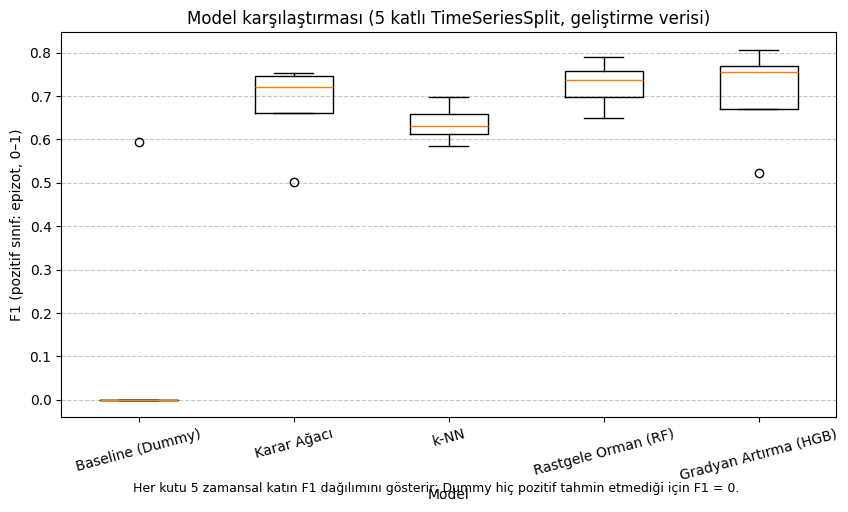

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [12]:
modeller = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Karar Ağacı": DecisionTreeClassifier(max_depth=6, random_state=SEED),
    "k-NN": KNeighborsClassifier(n_neighbors=7),
    "Rastgele Orman (RF)": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1),
    "Gradyan Artırma (HGB)": HistGradientBoostingClassifier(max_iter=100, random_state=SEED)
}

skorlar_f1, skorlar_bacc = {}, {}
print("Modeller zamana göre çapraz doğrulama ile değerlendiriliyor (yalnız geliştirme verisi)...\n")

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for isim, clf in modeller.items():
        pipe = Pipeline([('preprocessor', preprocessor), ('classifier', clf)])
        r = cross_validate(pipe, X_dev, y_dev, cv=tscv, scoring=['f1', 'balanced_accuracy'], n_jobs=-1)
        skorlar_f1[isim] = r['test_f1']
        skorlar_bacc[isim] = r['test_balanced_accuracy']
        print(f"✓ {isim:22s} -> F1: {r['test_f1'].mean():.4f} ± {r['test_f1'].std():.4f} | "
              f"B-Acc: {r['test_balanced_accuracy'].mean():.4f} ± {r['test_balanced_accuracy'].std():.4f}")

model_tablosu = pd.DataFrame({
    "F1 (ortalama ± std)": [f"{skorlar_f1[m].mean():.4f} ± {skorlar_f1[m].std():.4f}" for m in modeller],
    "Dengeli doğruluk (ortalama ± std)": [f"{skorlar_bacc[m].mean():.4f} ± {skorlar_bacc[m].std():.4f}" for m in modeller]
}, index=modeller.keys())
display(model_tablosu)

plt.figure(figsize=(10, 5))
etiket_arg = 'tick_labels' if tuple(int(p) for p in matplotlib.__version__.split('.')[:2]) >= (3, 9) else 'labels'
plt.boxplot([skorlar_f1[m] for m in modeller], **{etiket_arg: list(modeller.keys())})
plt.xlabel("Model")
plt.ylabel("F1 (pozitif sınıf: epizot, 0–1)")
plt.title("Model karşılaştırması (5 katlı TimeSeriesSplit, geliştirme verisi)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=15)
plt.figtext(0.5, -0.04, 'Her kutu 5 zamansal katın F1 dağılımını gösterir; Dummy hiç pozitif tahmin '
            'etmediği için F1 = 0.', ha='center', fontsize=9)
plt.show()

**Yorum:** _(Ölçüt seçiminin gerekçesi: sınıf oranı yukarıda; %50'ye yakınsa "dengesiz" gerekçesi kullanılamaz, F1 ve dengeli doğruluğu başka gerekçeyle savunun. Katlar arası std neden büyük? İlk katta eğitim verisi az ve mevsimler farklı.)_

### 2.2 Karar ağacının yorumu

In [13]:
# Ölçeklenmiş veride eşikler standart birimde çıkar ve yorumlanamaz. Ağaç ölçekleme istemediği için
# sayısal sütunlar ham birimde bırakılıyor. Karşılaştırmadaki AYNI ağaç (max_depth=6) yalnız
# geliştirme verisinde eğitiliyor; export_text max_depth=2 ile kök ve ilk iki düzeyi yazdırıyor.
pre_yorum = ColumnTransformer([('num', 'passthrough', num_cols),
                               ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
                              verbose_feature_names_out=False)
agac_yorum = Pipeline([('pre', pre_yorum),
                       ('clf', DecisionTreeClassifier(max_depth=6, random_state=SEED))]).fit(X_dev, y_dev)
isimler = list(agac_yorum.named_steps['pre'].get_feature_names_out())
print("=== KARAR AĞACI (max_depth=6) · KÖK VE İLK İKİ DÜZEY · ham birimler ===")
print(export_text(agac_yorum.named_steps['clf'], feature_names=isimler, max_depth=2, show_weights=True))
# show_weights: yapraktaki [temiz, epizot] kayıt sayısı. DEWP = çiy noktası (°C),
# Iws = birikimli rüzgâr hızı (m/s), PRES = basınç (hPa).

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

=== KARAR AĞACI (max_depth=6) · KÖK VE İLK İKİ DÜZEY · ham birimler ===
|--- DEWP <= -12.50
|   |--- Iws <= 12.07
|   |   |--- DEWP <= -17.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- DEWP >  -17.50
|   |   |   |--- truncated branch of depth 4
|   |--- Iws >  12.07
|   |   |--- cbwd_SE <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- cbwd_SE >  0.50
|   |   |   |--- truncated branch of depth 4
|--- DEWP >  -12.50
|   |--- cbwd_NW <= 0.50
|   |   |--- TEMP <= 5.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- TEMP >  5.50
|   |   |   |--- truncated branch of depth 4
|   |--- cbwd_NW >  0.50
|   |   |--- TEMP <= 5.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- TEMP >  5.50
|   |   |   |--- truncated branch of depth 4



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum:** _(Kök bölmesi hangi değişken, eşik fiziksel olarak ne anlama geliyor? Örn. yüksek çiy noktası = nemli, durgun hava; düşük birikimli rüzgâr = kirleticiler dağılmıyor; kuzeyli rüzgâr temiz hava getirir, güneyli rüzgâr sanayi bölgelerinden kirlilik taşır.)_

### 2.3 Optimist yanlılık

In [14]:
param_grid = {
    'classifier__max_depth': [3, 5, 8],
    'classifier__min_samples_split': [10, 50]
}
tree_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=SEED))
])

# 1. Standart GridSearchCV: seçimi yapan katlarda ölçülen skor (iyimser)
grid_search = GridSearchCV(tree_pipe, param_grid, cv=tscv, scoring='f1', n_jobs=-1)
grid_search.fit(X_dev, y_dev)
optimistic_score = grid_search.best_score_
optimistic_std = grid_search.cv_results_['std_test_score'][grid_search.best_index_]

# 2. İç içe çapraz doğrulama: dış katlar seçimde hiç kullanılmaz
nested_scores = cross_val_score(grid_search, X_dev, y_dev, cv=tscv, scoring='f1', n_jobs=-1)

print("=== OPTİMİST YANLILIK (F1) ===")
print(f"En iyi parametreler                : {grid_search.best_params_}")
print(f"GridSearchCV best_score_           : {optimistic_score:.4f} ± {optimistic_std:.4f}")
print(f"İç içe CV                          : {nested_scores.mean():.4f} ± {nested_scores.std():.4f}")
print(f"Fark (iyimserlik)                  : {(optimistic_score - nested_scores.mean()):.4f}")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

=== OPTİMİST YANLILIK (F1) ===
En iyi parametreler                : {'classifier__max_depth': 8, 'classifier__min_samples_split': 10}
GridSearchCV best_score_           : 0.6692 ± 0.0831
İç içe CV                          : 0.6477 ± 0.1209
Fark (iyimserlik)                  : 0.0215


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum:** _(Fark küçükse nedeni: ızgara yalnızca 6 kombinasyon, seçimin "şans" payı az. Farkın std'ye göre büyüklüğü ne?)_

### 2.4 İstatistiksel test: McNemar (Dietterich, 1998)

In [15]:
# Kat skorları üzerinde eşleştirilmiş t-testi, Dietterich'in yüksek I. tip hata verdiğini gösterdiği
# testtir; TimeSeriesSplit'te eğitim kümeleri iç içe geçtiği için sorun daha da büyür. 5×2 cv de veriyi
# rastgele ikiye böldüğü için zaman serisine uymaz. Bu yüzden: en iyi iki model geliştirme verisinde bir kez
# eğitilir, dokunulmayan test kümesinde McNemar uygulanır.
adaylar = sorted([m for m in skorlar_f1 if 'Baseline' not in m],
                 key=lambda m: skorlar_f1[m].mean(), reverse=True)
m1, m2 = adaylar[:2]
print(f"CV'ye göre en iyi iki model: {m1} ve {m2}")

tahmin = {}
for m in (m1, m2):
    pipe = Pipeline([('preprocessor', clone(preprocessor)), ('classifier', clone(modeller[m]))])
    tahmin[m] = pipe.fit(X_dev, y_dev).predict(X_test)
    print(f"  Test F1 · {m:22s}: {f1_score(y_test, tahmin[m]):.4f}")

dogru1 = tahmin[m1] == y_test.values
dogru2 = tahmin[m2] == y_test.values
b = int(np.sum(dogru1 & ~dogru2))   # yalnız m1 doğru
c = int(np.sum(~dogru1 & dogru2))   # yalnız m2 doğru
display(pd.DataFrame([[int(np.sum(dogru1 & dogru2)), b], [c, int(np.sum(~dogru1 & ~dogru2))]],
                     index=[f'{m1} doğru', f'{m1} yanlış'], columns=[f'{m2} doğru', f'{m2} yanlış']))

p_kesin = binomtest(min(b, c), b + c, 0.5).pvalue           # kesin (binom) McNemar
chi2_ist = (abs(b - c) - 1) ** 2 / (b + c)                    # süreklilik düzeltmeli
p_chi2 = chi2.sf(chi2_ist, df=1)
print(f"b = {b}, c = {c} · χ² = {chi2_ist:.3f}, p = {p_chi2:.4f} · kesin p = {p_kesin:.4f}")
print("Sonuç: fark anlamlı (p < 0.05)." if p_chi2 < 0.05 else "Sonuç: fark anlamlı değil (p ≥ 0.05).")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

CV'ye göre en iyi iki model: Rastgele Orman (RF) ve Gradyan Artırma (HGB)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

  Test F1 · Rastgele Orman (RF)   : 0.7530


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

  Test F1 · Gradyan Artırma (HGB) : 0.7849


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Gradyan Artırma (HGB) doğru,Gradyan Artırma (HGB) yanlış
Rastgele Orman (RF) doğru,5564,540
Rastgele Orman (RF) yanlış,950,1298


b = 540, c = 950 · χ² = 112.269, p = 0.0000 · kesin p = 0.0000
Sonuç: fark anlamlı (p < 0.05).


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum:** _(McNemar tahminlerin bağımsız olduğunu varsayar. Saatlik veride hatalar epizotlar içinde kümelenir, etkin örneklem daha küçüktür ve p-değeri olduğundan küçük çıkabilir; bunu sınırlılık olarak yazın.)_

### 2.5 Proje 2'ye aktarılacak model
_(Hangi model, hangi hiperparametreler, hangi değerlendirme protokolü (geliştirme/test ayrımı + TimeSeriesSplit(gap=24) + F1 ve dengeli doğruluk) ve gerekçesi.)_

## Bölüm 3 · Veri küpü ve birliktelik analizi

### 3.1 Veri küpü

In [16]:
# Olgu: epizot görülme oranı (kirlilik_epizodu ortalaması) · Boyutlar: yıl, ay, rüzgâr yönü
cube_df = df_clean[['year', 'month', 'cbwd', 'kirlilik_epizodu']].copy()

# A) ROLL-UP: yalnızca yıllık epizot oranı
rollup_year = cube_df.groupby('year')['kirlilik_epizodu'].mean() * 100
print("=== ROLL-UP: YILLIK EPİZOT ORANI (%) ===")
print(rollup_year.round(2))

# B) DRILL-DOWN: yıl × rüzgâr yönü
drilldown_cube = pd.pivot_table(cube_df, values='kirlilik_epizodu', index=['year'],
                                columns=['cbwd'], aggfunc='mean') * 100
print("\n=== DRILL-DOWN: YIL × RÜZGÂR YÖNÜ EPİZOT ORANI (%) ===")
display(drilldown_cube.round(2))

# C) Ay × rüzgâr yönü (mevsimsellik)
monthly_drilldown = pd.pivot_table(cube_df, values='kirlilik_epizodu', index=['month'],
                                   columns=['cbwd'], aggfunc='mean') * 100
print("\n=== AY × RÜZGÂR YÖNÜ EPİZOT ORANI (%) ===")
display(monthly_drilldown.round(2))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

=== ROLL-UP: YILLIK EPİZOT ORANI (%) ===
year
2010    51.55
2011    48.06
2012    47.04
2013    47.85
2014    48.04
Name: kirlilik_epizodu, dtype: float64

=== DRILL-DOWN: YIL × RÜZGÂR YÖNÜ EPİZOT ORANI (%) ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


cbwd,NE,NW,SE,cv
year,,,,
2010,42.60,32.25,65.18,68.48
2011,43.03,25.76,62.76,66.22
2012,40.41,25.57,61.16,58.48
2013,39.35,31.52,56.53,61.69
2014,43.20,31.04,54.96,59.73



=== AY × RÜZGÂR YÖNÜ EPİZOT ORANI (%) ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


cbwd,NE,NW,SE,cv
month,,,,
1,36.97,30.03,70.35,71.27
2,36.17,41.02,66.24,74.78
3,35.97,28.64,58.74,66.51
4,41.41,20.97,60.87,56.46
5,41.07,25.24,54.70,52.44
6,38.17,28.63,63.19,59.16
7,43.13,20.81,63.28,54.61
8,42.15,25.81,50.58,54.17
9,39.40,28.20,56.98,55.37


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [17]:
# Simpson paradoksu kontrolü
def simpson_kontrol(veri, x, z, olgu='kirlilik_epizodu'):
    """x'in ardışık değerleri arasında genel eğilim ile z alt gruplarındaki eğilimin yönünü karşılaştırır."""
    genel = veri.groupby(x)[olgu].mean()
    alt = veri.pivot_table(index=x, columns=z, values=olgu, aggfunc='mean')
    satir = []
    for a, b_ in zip(genel.index[:-1], genel.index[1:]):
        g = np.sign(genel[b_] - genel[a])
        yon = np.sign(alt.loc[b_] - alt.loc[a]).dropna()
        satir.append({x: f'{a}→{b_}',
                      'genel değişim (puan)': round((genel[b_] - genel[a]) * 100, 2),
                      'aynı yönde alt grup': int((yon == g).sum()),
                      'ters yönde alt grup': int((yon == -g).sum()),
                      'Simpson?': bool((yon == -g).all() and len(yon) > 0)})
    return pd.DataFrame(satir)

print("Yıllar arası değişim · alt gruplar: rüzgâr yönü")
display(simpson_kontrol(cube_df, 'year', 'cbwd'))
print("Rüzgâr yönlerinin yıllara göre payı (bileşim değişiyor mu?)")
display(pd.crosstab(cube_df['year'], cube_df['cbwd'], normalize='index').round(3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Yıllar arası değişim · alt gruplar: rüzgâr yönü


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,year,genel değişim (puan),aynı yönde alt grup,ters yönde alt grup,Simpson?
0,2010→2011,-3.49,3,1,False
1,2011→2012,-1.02,4,0,False
2,2012→2013,0.80,2,2,False
3,2013→2014,0.20,1,3,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Rüzgâr yönlerinin yıllara göre payı (bileşim değişiyor mu?)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


cbwd,NE,NW,SE,cv
year,,,,
2010,0.111,0.357,0.341,0.191
2011,0.104,0.361,0.333,0.203
2012,0.119,0.311,0.353,0.217
2013,0.121,0.310,0.349,0.221
2014,0.115,0.280,0.368,0.237


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum:** _(Bütün alt gruplar ters yöndeyse Simpson paradoksu vardır. Bir kısmı tersse genel eğilim kısmen bileşim değişiminden gelir. Bulunamaması da geçerli bir sonuçtur.)_

### 3.2 Birliktelik analizi · Seçenek B
Veride işlem (sepet) bilgisi yok, her satır bir saat. Sayısal öznitelikler ayrıklaştırılıp her saat "öznitelik = değer" öğelerinden oluşan bir işlem olarak ele alındı.

In [18]:
def ar_kurallari(sik, esik, n_islem):
    """mlxtend sürüm farkı: 0.23.2–0.23.3'te num_itemsets zorunlu."""
    try:
        return association_rules(sik, metric='confidence', min_threshold=esik)
    except TypeError:
        return association_rules(sik, num_itemsets=n_islem, metric='confidence', min_threshold=esik)

# Ayrıklaştırma (sınırların gerekçesi varsayım defterinde)
market_df = pd.DataFrame()
market_df['Sicaklik'] = pd.cut(df_clean['TEMP'], bins=[-50, 0, 15, 50],
                               labels=['Sicaklik_DonmaAlti', 'Sicaklik_Ilik', 'Sicaklik_Sicak'])
market_df['Ruzgar'] = pd.cut(df_clean['Iws'], bins=[-1, 5, 20, 1000],
                             labels=['Ruzgar_Durgun', 'Ruzgar_Orta', 'Ruzgar_Sert'])
# DEWP çiy noktasıdır (°C), bağıl nem değil
market_df['CiyNoktasi'] = pd.cut(df_clean['DEWP'], bins=[-50, -10, 10, 50],
                                 labels=['Ciy_Dusuk', 'Ciy_Orta', 'Ciy_Yuksek'])
market_df['Yon'] = 'Yon_' + df_clean['cbwd'].astype(str)
market_df['Epizot'] = df_clean['kirlilik_epizodu'].map({1: 'Epizot_Var', 0: 'Epizot_Yok'})

basket = pd.get_dummies(market_df)
print(f"İşlem tablosu: {basket.shape[0]} işlem, {basket.shape[1]} öğe")

frequent_itemsets = apriori(basket, min_support=0.05, use_colnames=True)
rules = ar_kurallari(frequent_itemsets, 0.5, len(basket))

HEDEF = frozenset({'Epizot_Epizot_Var'})
target_rules = rules[rules['consequents'] == HEDEF].copy()

def olcut_ekle(k):
    k = k.copy()
    sA, sB, sAB = k['antecedent support'], k['consequent support'], k['support']
    k['kulczynski'] = 0.5 * (sAB / sA + sAB / sB)          # 0.5 * (P(B|A) + P(A|B))
    k['IR'] = (sA - sB).abs() / (sA + sB - sAB)           # dengesizlik oranı
    k['oncul'] = k['antecedents'].apply(lambda s: ', '.join(sorted(s)))
    return k

goster = ['oncul', 'antecedent support', 'support', 'confidence', 'lift', 'kulczynski', 'IR']
target_rules = olcut_ekle(target_rules)
print(f"Sonucu Epizot_Var olan kural sayısı (min_support=0.05, min_conf=0.5): {len(target_rules)}")
for olcut in ['confidence', 'lift', 'kulczynski']:
    print(f"\n=== {{...}} → Epizot_Var · {olcut} sıralı ilk 10 ===")
    display(target_rules.sort_values(olcut, ascending=False)[goster].head(10).round(3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

İşlem tablosu: 41757 işlem, 15 öğe


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Sonucu Epizot_Var olan kural sayısı (min_support=0.05, min_conf=0.5): 30

=== {...} → Epizot_Var · confidence sıralı ilk 10 ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,oncul,antecedent support,support,confidence,lift,kulczynski,IR
44,"CiyNoktasi_Ciy_Orta, Sicaklik_Sicaklik_DonmaAlti",0.072,0.060,0.838,1.728,0.481,0.832
34,"Ruzgar_Ruzgar_Durgun, Sicaklik_Sicaklik_DonmaAlti",0.109,0.074,0.680,1.404,0.417,0.723
164,"CiyNoktasi_Ciy_Orta, Ruzgar_Ruzgar_Durgun, Sic...",0.113,0.076,0.676,1.394,0.417,0.713
214,"CiyNoktasi_Ciy_Orta, Ruzgar_Ruzgar_Durgun, Yon...",0.085,0.057,0.671,1.385,0.395,0.779
145,"CiyNoktasi_Ciy_Orta, Yon_Yon_cv",0.090,0.060,0.666,1.374,0.395,0.767
111,"CiyNoktasi_Ciy_Orta, Ruzgar_Ruzgar_Durgun",0.195,0.129,0.659,1.359,0.462,0.526
148,"CiyNoktasi_Ciy_Yuksek, Yon_Yon_SE",0.175,0.114,0.655,1.351,0.445,0.569
207,"CiyNoktasi_Ciy_Yuksek, Sicaklik_Sicaklik_Sicak...",0.169,0.110,0.651,1.344,0.440,0.580
217,"CiyNoktasi_Ciy_Yuksek, Ruzgar_Ruzgar_Durgun, Y...",0.084,0.054,0.647,1.334,0.380,0.778
149,"CiyNoktasi_Ciy_Yuksek, Yon_Yon_cv",0.086,0.055,0.643,1.327,0.379,0.774


... (4 outputs left out)


=== {...} → Epizot_Var · kulczynski sıralı ilk 10 ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,oncul,antecedent support,support,confidence,lift,kulczynski,IR
17,Ruzgar_Ruzgar_Durgun,0.494,0.295,0.596,1.229,0.602,0.014
29,Yon_Yon_SE,0.349,0.209,0.599,1.235,0.515,0.217
26,CiyNoktasi_Ciy_Yuksek,0.359,0.211,0.588,1.214,0.512,0.199
98,"CiyNoktasi_Ciy_Yuksek, Sicaklik_Sicaklik_Sicak",0.335,0.195,0.581,1.198,0.491,0.240
24,CiyNoktasi_Ciy_Orta,0.375,0.206,0.550,1.134,0.487,0.169
44,"CiyNoktasi_Ciy_Orta, Sicaklik_Sicaklik_DonmaAlti",0.072,0.060,0.838,1.728,0.481,0.832
111,"CiyNoktasi_Ciy_Orta, Ruzgar_Ruzgar_Durgun",0.195,0.129,0.659,1.359,0.462,0.526
30,Yon_Yon_cv,0.214,0.134,0.626,1.291,0.451,0.479
118,"Ruzgar_Ruzgar_Durgun, Yon_Yon_cv",0.206,0.130,0.629,1.297,0.448,0.496
148,"CiyNoktasi_Ciy_Yuksek, Yon_Yon_SE",0.175,0.114,0.655,1.351,0.445,0.569


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [19]:
# Nadir kategori: min_support=0.05 nadir öğeleri baştan eler. Eşiği düşürüp nadir öğe içeren kurallara bakıyoruz.
sik_dusuk = apriori(basket, min_support=0.005, use_colnames=True, max_len=3)
kural_dusuk = olcut_ekle(ar_kurallari(sik_dusuk, 0.0, len(basket)))
kural_dusuk = kural_dusuk[kural_dusuk['consequents'] == HEDEF]

oge_destek = basket.mean()
nadir_ogeler = set(oge_destek[oge_destek < 0.05].index)
if not nadir_ogeler:   # %5 altında öğe yoksa en düşük destekli 3 öğe
    nadir_ogeler = set(oge_destek.drop('Epizot_Epizot_Var').nsmallest(3).index)
print("Nadir öğeler:", {k: round(float(oge_destek[k]), 3) for k in nadir_ogeler})

nadir_kural = kural_dusuk[kural_dusuk['antecedents'].apply(lambda s: len(s & nadir_ogeler) > 0)]
print("\n=== Nadir öğe içeren kurallar: lift ve Kulczynski farkı ===")
display(nadir_kural.sort_values('lift', ascending=False)[goster].head(10).round(3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Nadir öğeler: {'Yon_Yon_cv': 0.214, 'Yon_Yon_NE': 0.114, 'Sicaklik_Sicaklik_DonmaAlti': 0.223}

=== Nadir öğe içeren kurallar: lift ve Kulczynski farkı ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,oncul,antecedent support,support,confidence,lift,kulczynski,IR
368,"CiyNoktasi_Ciy_Orta, Sicaklik_Sicaklik_DonmaAlti",0.072,0.060,0.838,1.728,0.481,0.832
415,"Sicaklik_Sicaklik_DonmaAlti, Yon_Yon_cv",0.044,0.031,0.719,1.484,0.392,0.888
212,"Ruzgar_Ruzgar_Durgun, Sicaklik_Sicaklik_DonmaAlti",0.109,0.074,0.680,1.404,0.417,0.723
404,"Sicaklik_Sicaklik_DonmaAlti, Yon_Yon_SE",0.040,0.027,0.667,1.375,0.361,0.892
1435,"CiyNoktasi_Ciy_Orta, Yon_Yon_cv",0.090,0.060,0.666,1.374,0.395,0.767
1483,"CiyNoktasi_Ciy_Yuksek, Yon_Yon_cv",0.086,0.055,0.643,1.327,0.379,0.774
697,"Sicaklik_Sicaklik_Ilik, Yon_Yon_cv",0.076,0.048,0.634,1.308,0.367,0.798
1117,"Ruzgar_Ruzgar_Durgun, Yon_Yon_cv",0.206,0.130,0.629,1.297,0.448,0.496
170,Yon_Yon_cv,0.214,0.134,0.626,1.291,0.451,0.479
961,"Sicaklik_Sicaklik_Sicak, Yon_Yon_cv",0.095,0.055,0.577,1.189,0.345,0.742


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum:** _(Nadir öncülde lift yüksek görünebilir; Kulczynski P(B|A) ile P(A|B)'nin ortalaması olduğu için A nadirse düşük kalır. IR yüksekse Kulczynski ~0.5 "nötr" değil "dengesiz" okunmalı (Wu, Chen ve Han, 2010). En güçlü kurallardaki öğeler (çiy noktası, rüzgâr, yön) karar ağacının bölmeleri ve Ek paket 1'deki permütasyon önemiyle örtüşüyor mu? Üç kuralı alan bilgisiyle yorumlayın.)_

### 3.3 Weka Apriori ile kontrol

In [20]:
arff_lines = [
    "@relation beijing_apriori\n",
    f"@attribute Sicaklik {{{','.join(market_df['Sicaklik'].cat.categories)}}}",
    f"@attribute Ruzgar {{{','.join(market_df['Ruzgar'].cat.categories)}}}",
    f"@attribute CiyNoktasi {{{','.join(market_df['CiyNoktasi'].cat.categories)}}}",
    f"@attribute Yon {{{','.join(sorted(market_df['Yon'].unique()))}}}",
    f"@attribute Epizot {{{','.join(sorted(market_df['Epizot'].unique()))}}}\n",
    "@data"
]
for row in market_df.itertuples(index=False):
    arff_lines.append(",".join(map(str, row)))

with open("beijing_apriori.arff", "w", encoding="utf-8") as f:
    f.write("\n".join(arff_lines))
print("beijing_apriori.arff oluşturuldu.")
print("Weka Associate → Apriori ayarları: lowerBoundMinSupport=0.05, metricType=Confidence, minMetric=0.5,")
print("numRules=1000 (varsayılan 10 yetmez), car=True ve classIndex=Epizot (yalnız hedefe yönelik kurallar).")

try:   # Colab dışında (GitHub'dan yerel çalıştırma) hata vermesin
    from google.colab import files
    files.download('beijing_weka.arff')
    files.download('beijing_apriori.arff')
except ImportError:
    pass

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

beijing_apriori.arff oluşturuldu.
Weka Associate → Apriori ayarları: lowerBoundMinSupport=0.05, metricType=Confidence, minMetric=0.5,
numRules=1000 (varsayılan 10 yetmez), car=True ve classIndex=Epizot (yalnız hedefe yönelik kurallar).


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Weka çıktısı (özet):**

```
weka.associations.Apriori -N 1000 -T 0 -C 0.5 -D 0.05 -U 1.0 -M 0.05 -S -1.0 -A -c -1
Minimum support: 0.05 (2088 instances) · Minimum metric <confidence>: 0.5
Number of cycles performed: 19
Size of set of large itemsets L(1): 25 · L(2): 47 · L(3): 12
Best rules found: 59  (30 → Epizot_Var, 29 → Epizot_Yok)

  1. Ruzgar=Ruzgar_Sert CiyNoktasi=Ciy_Dusuk Yon=Yon_NW 3788 ==> Epizot=Epizot_Yok 3651    conf:(0.96)
  2. Ruzgar=Ruzgar_Sert CiyNoktasi=Ciy_Dusuk 4487 ==> Epizot=Epizot_Yok 4215    conf:(0.94)
  7. Sicaklik=Sicaklik_DonmaAlti CiyNoktasi=Ciy_Orta 3005 ==> Epizot=Epizot_Var 2518    conf:(0.84)
 18. Sicaklik=Sicaklik_DonmaAlti Ruzgar=Ruzgar_Durgun 4557 ==> Epizot=Epizot_Var 3101    conf:(0.68)
 25. CiyNoktasi=Ciy_Yuksek Yon=Yon_SE 7288 ==> Epizot=Epizot_Var 4774    conf:(0.66)
 31. Yon=Yon_cv 8944 ==> Epizot=Epizot_Var 5598    conf:(0.63)
 39. Ruzgar=Ruzgar_Durgun 20647 ==> Epizot=Epizot_Var 12303    conf:(0.6)
```

**Yorum:** Weka Apriori aynı eşiklerle (lowerBoundMinSupport = 0,05, minMetric = 0,5, numRules = 1000, car = True) çalıştırıldı ve 59 sınıf birliktelik kuralı üretti: 30'unun sonucu Epizot_Var, 29'unun Epizot_Yok. Python tarafında sonucu Epizot_Var olan kural sayısı da 30'dur ve her kuralın öncül ve kural kayıt sayıları Weka ile birebir aynıdır (örn. {Sıcaklık = donma altı, Çiy noktası = orta}: 3005 kayıt → 2518 epizot, güven 0,84). Weka'nın raporladığı L(1) = 25, L(2) = 47, L(3) = 12 değerleri Python'daki sık öğe kümesi sayılarından farklıdır, çünkü car modunda Weka yalnızca sınıf değerini içeren "öncül + sınıf" kümelerini sayar. Bu, kural kümesinde değil sayma biçiminde bir farktır.

Weka çıktısında en yüksek güvenli kurallar temiz havaya ait: {kuvvetli rüzgâr, düşük çiy noktası, kuzeybatı yönü} → Epizot_Yok (güven 0,96). Epizot kurallarının güveni ise en fazla 0,84. Yani bu ayrıklaştırmayla temiz hava koşulları, kirli hava koşullarından daha keskin tanımlanabiliyor. Kuzeybatıdan esen kuru ve kuvvetli rüzgâr kirleticileri dağıtırken, epizotlar durgun ya da değişken rüzgârla (cv), güneydoğu rüzgârıyla ve kışın donma altı sıcaklıklarla birlikte görülüyor. Weka car modunda yalnızca güveni raporladığı için lift ve Kulczynski karşılaştırması Python tarafında (3.2) yapıldı.

## Ek paket 1 · Topluluk yöntemleri ve öznitelik önemi

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

=== EK PAKET 1: TOPLULUK YÖNTEMLERİ VE ÖZNİTELİK ÖNEMİ ===


Görüntülenen çıkış son 5000 satıra kısaltıldı.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tz

CV'ye göre seçilen ccp_alpha = 1.63e-02 · 2 yaprak · test F1 = 0.6762


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' depr

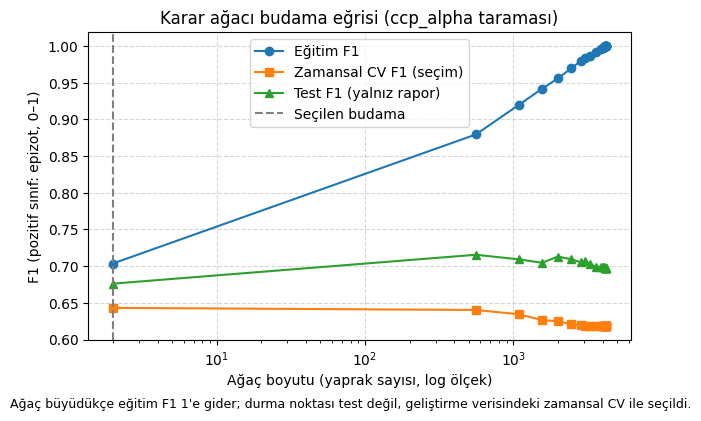

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,agac,oob_hata,test_hata
0,1,0.4092,0.3287
1,2,0.3590,0.3190
2,5,0.2818,0.2945
3,10,0.2421,0.2847
4,20,0.2237,0.2706
5,50,0.2122,0.2674
6,100,0.2087,0.2692
7,200,0.2098,0.2654
8,300,0.2083,0.2650
9,500,0.2092,0.2662


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarni

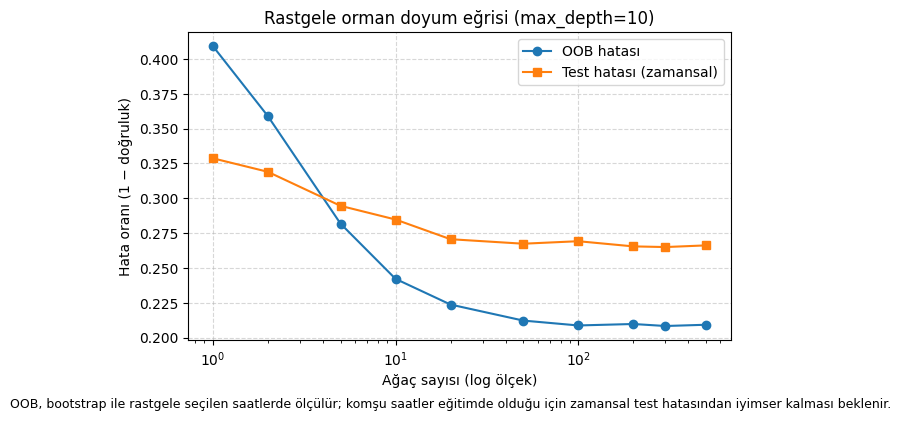

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,oznitelik,gini,perm_ort,perm_std,gini_sira,perm_sira
0,DEWP,0.2588,0.1352,0.0048,1,1
1,TEMP,0.1073,0.0774,0.0033,3,2
2,Iws,0.1828,0.0368,0.0020,2,3
3,cbwd_SE,0.0521,0.0307,0.0023,7,4
4,month,0.0689,0.0264,0.0015,6,5
5,cbwd_NW,0.0833,0.0149,0.0017,4,6
6,hour,0.0390,0.0086,0.0008,9,7
7,PRES,0.0724,0.0067,0.0019,5,8
8,day,0.0404,0.0033,0.0012,8,9
9,cbwd_NE,0.0116,0.0020,0.0009,13,10


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Rastgele sütun · Gini sırası: 12/15 · permütasyon sırası: 15/15 · perm. önemi: -0.0006 ± 0.0008


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

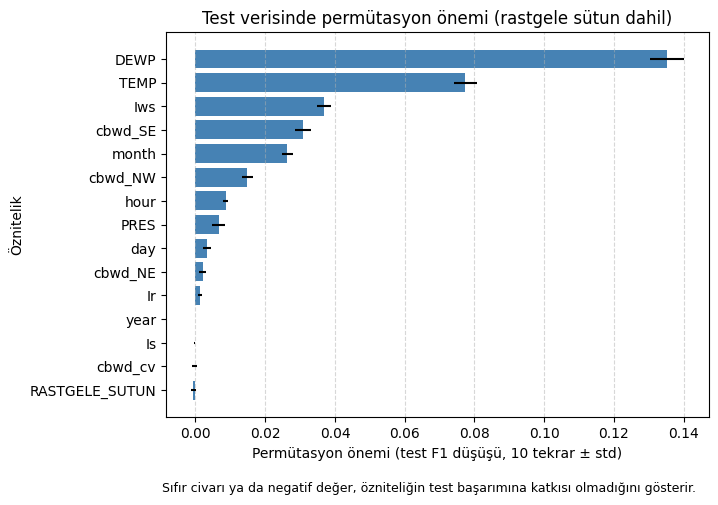

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [21]:
print("=== EK PAKET 1: TOPLULUK YÖNTEMLERİ VE ÖZNİTELİK ÖNEMİ ===")
# Bütün geliştirme / test verisi kullanılıyor (alt örneklem yok). Ağaçlar ölçekleme istemediği için
# sayısal sütunlar ham birimde.
pre_ep = ColumnTransformer([('num', 'passthrough', num_cols),
                            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)],
                           verbose_feature_names_out=False)
Xd = pre_ep.fit_transform(X_dev)          # yalnız geliştirme verisiyle fit
Xt = pre_ep.transform(X_test)
yd, yt = y_dev.values, y_test.values
ep_isimler = list(pre_ep.get_feature_names_out())

# -------------------------------------------------------------
# 1. Karar ağacı budama eğrisi (ccp_alpha)
# -------------------------------------------------------------
yol = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(Xd, yd)
alfalar = np.unique(yol.ccp_alphas[:-1])                   # sonuncusu yalnız kökü bırakır
alfalar = alfalar[np.unique(np.geomspace(1, len(alfalar), 25).astype(int) - 1)]

budama = []
for a in alfalar:
    agac = DecisionTreeClassifier(random_state=SEED, ccp_alpha=a)
    cv_f1 = cross_val_score(agac, Xd, yd, cv=tscv, scoring='f1').mean()   # seçim yalnız geliştirmede
    agac.fit(Xd, yd)
    budama.append({'ccp_alpha': a, 'yaprak': agac.get_n_leaves(),
                   'egitim_f1': f1_score(yd, agac.predict(Xd)),
                   'cv_f1': cv_f1,
                   'test_f1': f1_score(yt, agac.predict(Xt))})
budama = pd.DataFrame(budama)
secilen = budama.loc[budama['cv_f1'].idxmax()]
print(f"CV'ye göre seçilen ccp_alpha = {secilen['ccp_alpha']:.2e} · {int(secilen['yaprak'])} yaprak · "
      f"test F1 = {secilen['test_f1']:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(budama['yaprak'], budama['egitim_f1'], 'o-', label='Eğitim F1')
plt.plot(budama['yaprak'], budama['cv_f1'], 's-', label='Zamansal CV F1 (seçim)')
plt.plot(budama['yaprak'], budama['test_f1'], '^-', label='Test F1 (yalnız rapor)')
plt.axvline(secilen['yaprak'], color='grey', ls='--', label='Seçilen budama')
plt.xscale('log')
plt.xlabel('Ağaç boyutu (yaprak sayısı, log ölçek)')
plt.ylabel('F1 (pozitif sınıf: epizot, 0–1)')
plt.title('Karar ağacı budama eğrisi (ccp_alpha taraması)')
plt.legend()
plt.grid(True, ls='--', alpha=0.5)
plt.figtext(0.5, -0.06, "Ağaç büyüdükçe eğitim F1 1'e gider; durma noktası test değil, "
            "geliştirme verisindeki zamansal CV ile seçildi.", ha='center', fontsize=9)
plt.show()

# -------------------------------------------------------------
# 2. Rastgele orman doyum eğrisi: 1 → 500 ağaç
# -------------------------------------------------------------
# warm_start: ağaçlar üst üste eklenir, her adımda baştan eğitilmez
agac_sayilari = [1, 2, 5, 10, 20, 50, 100, 200, 300, 500]
rf_doyum = RandomForestClassifier(max_depth=10, oob_score=True, warm_start=True,
                                  random_state=SEED, n_jobs=-1)
doyum = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')   # çok az ağaçta bazı kayıtların OOB tahmini olmaz
    for n in agac_sayilari:
        rf_doyum.set_params(n_estimators=n)
        rf_doyum.fit(Xd, yd)
        doyum.append({'agac': n, 'oob_hata': 1 - rf_doyum.oob_score_,
                      'test_hata': 1 - rf_doyum.score(Xt, yt)})
doyum = pd.DataFrame(doyum)
display(doyum.round(4))

plt.figure(figsize=(7, 4))
plt.plot(doyum['agac'], doyum['oob_hata'], 'o-', label='OOB hatası')
plt.plot(doyum['agac'], doyum['test_hata'], 's-', label='Test hatası (zamansal)')
plt.xscale('log')
plt.xlabel('Ağaç sayısı (log ölçek)')
plt.ylabel('Hata oranı (1 − doğruluk)')
plt.title('Rastgele orman doyum eğrisi (max_depth=10)')
plt.legend()
plt.grid(True, ls='--', alpha=0.5)
plt.figtext(0.5, -0.06, 'OOB, bootstrap ile rastgele seçilen saatlerde ölçülür; komşu saatler eğitimde '
            'olduğu için zamansal test hatasından iyimser kalması beklenir.', ha='center', fontsize=9)
plt.show()

# -------------------------------------------------------------
# 3. Rastgele sütun: Gini ve permütasyon önemi
# -------------------------------------------------------------
rng = np.random.default_rng(SEED)
Xd_g = np.column_stack([Xd, rng.normal(size=len(Xd))])
Xt_g = np.column_stack([Xt, rng.normal(size=len(Xt))])
isim_g = ep_isimler + ['RASTGELE_SUTUN']

rf_onem = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1).fit(Xd_g, yd)
perm = permutation_importance(rf_onem, Xt_g, yt, scoring='f1', n_repeats=10,
                              random_state=SEED, n_jobs=-1)
onem = pd.DataFrame({'oznitelik': isim_g,
                     'gini': rf_onem.feature_importances_,
                     'perm_ort': perm.importances_mean,
                     'perm_std': perm.importances_std})
onem['gini_sira'] = onem['gini'].rank(ascending=False).astype(int)
onem['perm_sira'] = onem['perm_ort'].rank(ascending=False).astype(int)
onem = onem.sort_values('perm_ort', ascending=False).reset_index(drop=True)
display(onem.round(4))
r = onem.set_index('oznitelik').loc['RASTGELE_SUTUN']
print(f"Rastgele sütun · Gini sırası: {int(r['gini_sira'])}/{len(onem)} · "
      f"permütasyon sırası: {int(r['perm_sira'])}/{len(onem)} · perm. önemi: {r['perm_ort']:.4f} ± {r['perm_std']:.4f}")

plt.figure(figsize=(7, 5))
plt.barh(onem['oznitelik'], onem['perm_ort'], xerr=onem['perm_std'], color='steelblue')
plt.gca().invert_yaxis()
plt.xlabel('Permütasyon önemi (test F1 düşüşü, 10 tekrar ± std)')
plt.ylabel('Öznitelik')
plt.title('Test verisinde permütasyon önemi (rastgele sütun dahil)')
plt.grid(axis='x', ls='--', alpha=0.5)
plt.figtext(0.5, -0.04, 'Sıfır civarı ya da negatif değer, özniteliğin test başarımına katkısı '
            'olmadığını gösterir.', ha='center', fontsize=9)
plt.show()

**Yorum:** _(Budama: nerede durulmalı, neden? Doyum: kaç ağaçtan sonra hata düzleşiyor; OOB ile test hatası arasındaki fark ne anlatıyor? Önem: Gini önemi eğitim bölmelerinden gelir ve çok değer alan sürekli sütunları kayırır, rastgele sütun orta sıralara çıkabilir; permütasyon önemi testte ölçüldüğü için ~0'da kalır. year ve day'in negatif/sıfır permütasyon önemi ne anlatıyor?)_

## Varsayım defteri
- **Epizot eşiği 75 µg/m³:** Çin GB 3095-2012, 24 saatlik II. sınıf sınırı; saatlik değere uygulandı.
- **Tahmin anı:** aynı saatin hava koşullarıyla anlık tespit; erken uyarı iddia edilmiyor.
- **Bölme:** son %20 dokunulmayan test; geliştirmede TimeSeriesSplit(5, gap=24). Tekrarlı katmanlı CV kullanılmadı, çünkü karıştırma geleceği eğitime sızdırır (Kaufman vd., 2012).
- **İstatistiksel test:** McNemar; kat skorlarında t-testi ve 5×2 cv kullanılmadı (Dietterich, 1998).
- **Ölçüt:** F1 (pozitif sınıf) ve dengeli doğruluk: _(gerekçe)_
- **year ve day:** _(tutuldu mu, neden)_
- **Ayrıklaştırma sınırları:** sıcaklık 0 / 15 °C, rüzgâr 5 / 20 m/s, çiy noktası −10 / 10 °C: _(gerekçe)_
- **Hedefi eksik satırlar çıkarıldı:** hedef doldurulamaz.

# BLM5103 Veri Madenciliği — Proje 1
**Konu 9:** Pekin PM2.5 Veri Seti ile Hava Kirliliği Epizodu Tahmini ve Birliktelik Analizi

---

## 🎥 Proje Sunum Videosu
> **Sunum Video Bağlantısı (Google Drive):** [BURAYA_GOOGLE_DRIVE_VIDEO_LINKINI_YAPISTIRIN]  
*(Erişim İzni: "Bağlantıya sahip olan herkes görüntüleyebilir" olarak ayarlanmıştır.)*

---

## 👥 Grup Bilgileri ve Görev Dağılımı (Grup Büyüklüğü: 4 Kişi)

| Öğrenci Adı Soyadı | Öğrenci No | Sunumda ve Projede Sorumlu Olduğu Bölüm |
| :--- | :--- | :--- |
| **Süleyman Balsak** | 254312022 | **Bölüm 1:** Veri Künyesi, Eksik Değer Analizi, Veri Sızıntısı Deneyi ve Weka J48 Bağımsız Kontrolü |
| **Seda Erten** | 254312008 | **Bölüm 2:** 5 Modelin `TimeSeriesSplit` ile Kıyaslanması, Karar Ağacı Kuralları (`export_text`), Nested CV ve Eşleştirilmiş t-Testi |
| **İlkin Urcan** | 244329078 | **Bölüm 3:** Veri Küpü (Roll-up / Drill-down), Simpson Paradoksu, Apriori Kural Madenciliği ve Weka Apriori Doğrulaması |
| **Aslıhan Semiz Varlı** | 254329024 | **Ek Paket 1:** `ccp_alpha` Budama Eğrisi, Random Forest Doyum Eğrisi ve Yapay Rastgele Gürültü Sütunu Deneyi |

---

#
### Kapsanan Başlıklar (4 Kişilik Grup Müfredatı)
1. **Bölüm 1 (Ön İşleme & Sızıntı Deneyi):** Zaman serisine uygun kronolojik eksik veri tamamlama, sızıntısız `Pipeline`, ham hedef özniteliğin model üzerindeki sızıntı (data leakage) etkisinin deneysel kanıtı ve Weka J48 bağımsız kontrolü.
2. **Bölüm 2 (Model Değerlendirme):** 5 farklı sınıflandırıcının (Dummy, Karar Ağacı, k-NN, Random Forest, HistGradientBoosting) 5 katlı `TimeSeriesSplit` ile değerlendirilmesi, karar ağacı bölmelerinin alan bilgisiyle yorumu, iç içe (Nested) CV ile optimist yanlılık analizi ve Dietterich (1998) eşleştirilmiş t-testi.
3. **Bölüm 3 (Veri Küpü & Apriori):** Roll-up ve Drill-down ile çok boyutlu epizot incelemesi, Simpson Paradoksu tartışması, ayrıklaştırma ile işlem tablosu, Python ve Weka Apriori kural madenciliği doğrulaması.
4. **Ek Paket 1 (Topluluk Yöntemleri & Öznitelik Önemi):** `ccp_alpha` budama eğrisi, Random Forest ağaç sayısı doyum eğrisi ve yapay rastgele gürültü sütunu ile Gini (MDI) vs Test Permütasyon önemi kıyaslaması.

---

## 📁 Dizin Yapısı
```text
├── README.md                      # Proje tanıtımı, video bağlantısı ve 4 kişilik grup görev dağılımı
└── proje1/
    └── Proje_1_Konu_9.ipynb       # Tüm analiz adımlarını ve çıktıları içeren çalıştırılmış Colab defteri

## Yapay zekâ beyanı
_(Hangi araç, hangi aşamada ve ne için kullanıldı. Örn.: kodun yönergeye uygunluk açısından gözden geçirilmesi ve düzeltme önerileri için Claude kullanıldı.)_

## Kaynaklar
- Liang, X. vd. (2015). Assessing Beijing's PM2.5 pollution. Proceedings of the Royal Society A, 471, 20150257. · UCI Machine Learning Repository: Beijing PM2.5 Data.
- Kaufman, S., Rosset, S., Perlich, C. ve Stitelman, O. (2012). Leakage in data mining. ACM TKDD, 6(4).
- Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. Neural Computation, 10(7), 1895–1923.
- Wu, T., Chen, Y. ve Han, J. (2010). Re-examination of interestingness measures in pattern mining. DMKD, 21(3), 371–397.
- Han, J., Kamber, M. ve Pei, J. Data Mining: Concepts and Techniques, 8. bölüm.
- Çin Ulusal Ortam Hava Kalitesi Standardı GB 3095-2012.